# 03 · Estado enriquecido, mercados extra y serie real

Tres pruebas para ir más allá de los mínimos, con **Q-Learning y SARSA**, resultados ejecutados y controles comunes:

1. **Estado enriquecido:** comprobar si añadir distancia a una media larga y volatilidad mejora los mercados de reversión y regímenes, donde el estado del taller puede quedarse corto.
2. **Mercados extra:** una tendencia persistente y una difusión con saltos. Buscamos distinguir una señal aprendible de un riesgo que los indicadores no pueden anticipar.
3. **Serie real:** cierres diarios del S&P 500, separando entrenamiento (2017–2021), validación (2022–2023) y test (2024–2025).

La pregunta no es «¿sale una curva bonita?», sino **qué mejora al cambiar el estado y qué generaliza a datos no vistos**. Se mantienen las acciones, la comisión del 0,1 %, la recompensa y la contabilidad del taller. El código nuevo está en `src/extras.py`; `SimpleTradingEnv` y los cuatro generadores originales no cambian.

**Salidas:** `results/03_extras.csv` (esquema común para el 04), resultados por semilla y episodio, deltas emparejados, bloques reales, conclusiones y figuras `03_*.png`.

In [1]:
import os, sys, json
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if not (ROOT / "src" / "extras.py").exists():
    raise RuntimeError("Ejecuta este notebook desde la raíz del repositorio o desde notebooks/")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from src.env import SimpleTradingEnv
from src.agents import BuyHoldAgent
from src.experiment import RESULT_COLUMNS, RESULTS_DIR, save_results
from src.style import setup, savefig, AGENT_COLORS
from src.extras import (
    SYNTHETIC_MARKETS, LABELS, ALGORITHMS, FeatureTradingEnv, CashAgent,
    prepare, causal_features, fit_encoder, calibration_series, evaluation_series,
    real_data, real_indices, run_training, run_test, baselines, paired_state_effect,
    load_model, run_extra_episode, real_blocks, code_fingerprint,
)
from src.markets import make_prices

setup()
pd.set_option("display.precision", 4)
QUICK = os.environ.get("NB_QUICK") == "1"
RECALCULAR = False
N_JOBS = min(6, max(1, (os.cpu_count() or 2) // 2))
SEEDS = [0] if QUICK else [0, 1, 2, 3, 4]
N_EP = 25 if QUICK else 800
N_STEPS = 160 if QUICK else 500
N_VAL = 5 if QUICK else 100
N_TEST = 8 if QUICK else 200
SUF = "_quick" if QUICK else ""
MARKETS_03 = [*SYNTHETIC_MARKETS, "sp500_real"]
BASE = dict(alpha=0.001, gamma=0.9, epsilon_decay=0.99, epsilon_min=0.01,
            n_episodes=N_EP, n_steps=N_STEPS, n_val=N_VAL, n_test=N_TEST, real_window=252)
def figure(fig, name):
    return savefig(fig, name + SUF)

print(f"{'PRUEBA RÁPIDA' if QUICK else 'EXPERIMENTO COMPLETO'} · {len(SEEDS)} semillas · {N_EP} episodios"
      f" · {N_JOBS} procesos · {N_TEST} series sintéticas de test")
print("La serie real tiene un único recorrido de test; las semillas son entrenamientos, no historias independientes.")

EXPERIMENTO COMPLETO · 5 semillas · 800 episodios · 6 procesos · 200 series sintéticas de test
La serie real tiene un único recorrido de test; las semillas son entrenamientos, no historias independientes.


## 1. Protocolo: comparación controlada y sin mirar al futuro

| Elemento | Decisión |
|---|---|
| Algoritmos | Q-Learning y SARSA del módulo común; se conserva su orden de actualización |
| Estado base | Tendencia del taller (10 bins) × posición: **20 estados** |
| Estado enriquecido | Tendencia (10) × distancia MA30 (3) × volatilidad20 (3) × posición: **180 estados** si los cuantiles son distintos |
| Hiperparámetros | α=0,001; γ=0,9; ε inicial=1, decaimiento=0,99, mínimo=0,01; 800 episodios en ambos estados |
| Sintéticos | 500 precios por episodio; series nuevas; train `seed*10_000+episodio`, validación desde `50_000`, test desde `100_000` |
| Cuantiles | Solo 50 series sintéticas de train; para la serie real, solo 2017–2021. Se congelan antes de validar y evaluar |
| Comparación | Mismas series, presupuesto, algoritmos y semillas en ambos estados. Únicamente cambia la información del estado |
| Test | Sin aprendizaje, política greedy. Cinco entrenamientos; 200 historias sintéticas compartidas |
| Controles | Aleatorio, buy & hold y **no operar**, con la misma contabilidad |

Se fija la configuración **antes de evaluar**: no se elige el mejor resultado de test ni se ajustan hiperparámetros a posteriori. Validación es un diagnóstico separado, no una búsqueda adicional. Así se mide el efecto de ampliar la observación a presupuesto fijo; **no se compara con los hiperparámetros ya optimizados de 01–02**.

El estado enriquecido tiene nueve veces más celdas: puede aportar información y también sufrir menor cobertura. Un resultado negativo no demuestra que la información sea inútil ni que la configuración sea óptima.

In [2]:
configs = [dict(BASE, mercado=m, algoritmo=a, estado=e, seed=s)
           for m in MARKETS_03 for a in ALGORITHMS
           for e in ("base", "enriquecido") for s in SEEDS]
protocol = pd.DataFrame(configs)
display(protocol.groupby(["mercado", "estado"]).size().rename("entrenamientos").unstack())
assert max(SEEDS) * 10_000 + N_EP <= 50_000
print(f"{len(configs)} entrenamientos; todas las configuraciones están fijadas antes del test.")

estado,base,enriquecido
mercado,,
regimenes,10,10
reversion_media,10,10
saltos,10,10
sp500_real,10,10
tendencia_persistente,10,10


100 entrenamientos; todas las configuraciones están fijadas antes del test.


## 2. Qué contiene el estado enriquecido

Para decidir en el instante $t$ se utilizan únicamente precios hasta $p_t$:

$$x_t^{corto}=\operatorname{clip}\left(\frac{p_t-\operatorname{MA}_6(t)}{\operatorname{MA}_6(t)},-1,1\right),\qquad
x_t^{largo}=\operatorname{clip}\left(\frac{p_t-\operatorname{MA}_{30}(t)}{\operatorname{MA}_{30}(t)},-1,1\right).$$

$$v_t=\operatorname{std}\left(r_{t-19},\ldots,r_t\right),\qquad r_t=p_t/p_{t-1}-1.$$

Las ventanas incluyen el cierre actual. En los primeros pasos se usa la historia disponible, sin rellenar con el futuro. El estado base conserva la señal original de seis precios. El enriquecido añade **distancia relativa a una media larga** y **volatilidad realizada**; no recibe el régimen oculto del generador ni una media de equilibrio conocida de antemano.

- En **reversión**, la distancia larga puede distinguir una caída transitoria de un precio todavía alto.
- En **regímenes**, la volatilidad puede ayudar a identificar el régimen bajista, más volátil, y la media larga ofrece más contexto.
- Ninguna de estas variables garantiza la propiedad de Markov ni permite predecir saltos independientes.

,estado,n_estados,bins
0,base,20,10 × 2 posiciones
1,enriquecido,180,10 × 3 × 3 × 2 posiciones


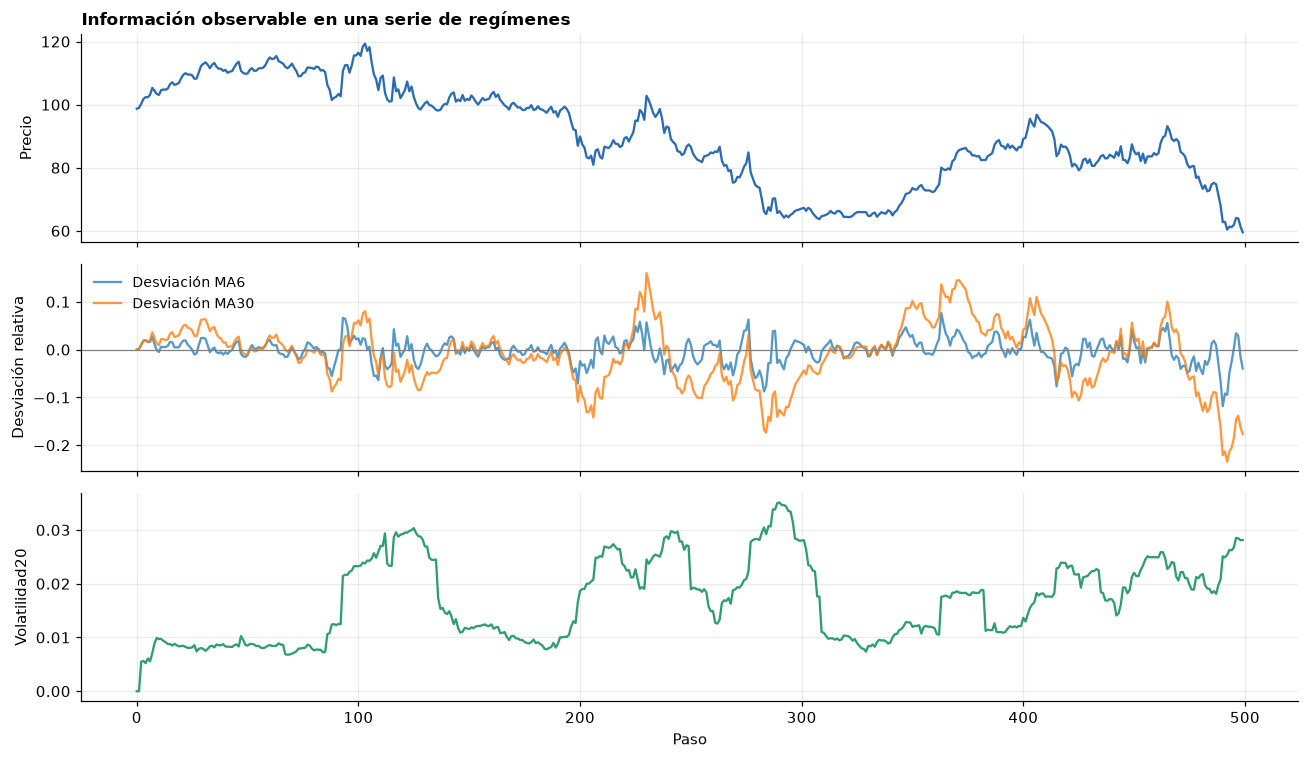

In [3]:
sample = prepare(make_prices("regimenes", N_STEPS, 17))  # serie de train, no seleccionada en test
encoders_demo = {e: fit_encoder(calibration_series("regimenes", N_STEPS), e)
                 for e in ("base", "enriquecido")}
display(pd.DataFrame([
    {"estado": e, "n_estados": enc.n_states,
     "bins": " × ".join(str(len(x)+1) for x in enc.edges) + " × 2 posiciones"}
    for e, enc in encoders_demo.items()]))
fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
axes[0].plot(sample.prices, color=AGENT_COLORS["qlearning"])
axes[0].set_ylabel("Precio"); axes[0].set_title("Información observable en una serie de regímenes", loc="left")
axes[1].plot(sample.features[:, 0], label="Desviación MA6", alpha=.75)
axes[1].plot(sample.features[:, 1], label="Desviación MA30", alpha=.8)
axes[1].axhline(0, color="gray", lw=.8); axes[1].set_ylabel("Desviación relativa"); axes[1].legend()
axes[2].plot(sample.features[:, 2], color=AGENT_COLORS["sarsa"])
axes[2].set_ylabel("Volatilidad20"); axes[2].set_xlabel("Paso")
fig.tight_layout(); figure(fig, "03_estado_features"); plt.show()

### Comprobaciones antes de entrenar

Se comprueba que alterar el futuro no cambie indicadores pasados; que la subclase ejecute las mismas acciones, recompensas, comisiones y balances que el entorno original; y que los índices de la tabla Q sean válidos. El test comprueba además que Q permanezca congelada.

In [4]:
prices = make_prices("regimenes", 160, 7)
changed = prices.copy(); changed[80:] *= 1.5
assert np.array_equal(causal_features(prices)[:80], causal_features(changed)[:80])
env_original, env_extra = SimpleTradingEnv(prices), FeatureTradingEnv(prepare(prices))
env_original.reset(); env_extra.reset()
for action in np.random.default_rng(3).integers(3, size=len(prices)-6):
    o1, r1, d1, t1, info1 = env_original.step(int(action))
    o2, r2, d2, t2, info2 = env_extra.step(int(action))
    assert (r1, d1, t1, info1) == (r2, d2, t2, info2)
    assert np.isclose(o1[0], o2[0]) and o1[1] == o2[-1]
for encoder in encoders_demo.values():
    codes = encoder.codes(sample.features)
    assert codes.min() >= 0 and codes.max() + 1 < encoder.n_states
print("OK: causalidad, contabilidad original e índices del estado.")

OK: causalidad, contabilidad original e índices del estado.


## 3. Mercados extra: hipótesis contrastables

Los dos generadores se añaden al final de `src/markets.py`. Se registran explícitamente al importar `src/extras.py`, de modo que los notebooks 00–02 no amplían sus barridos por el mero hecho de importar `markets`.

| Mercado | Generación | Hipótesis antes de medir |
|---|---|---|
| Tendencia persistente | Log-retorno con media +0,004 o −0,004, ruido σ=0,008 y cambio de signo con p=0,01 | Las tendencias duran unos 100 pasos en promedio; hay señal en la historia reciente. El agente debería aprender a entrar en subidas y salir en bajadas |
| Difusión + saltos | Log-retorno base N(0,0002−σ²/2, σ), σ=0,012; salto independiente con p=0,015 y tamaño N(−0,04, 0,06) | Los saltos no son anticipables con el pasado. Un resultado de no operar puede ser sensato y no se interpretará como predicción de caídas |

Son mecanismos didácticos, no modelos calibrados a un activo. La tendencia empieza alcista, por lo que también se conserva ese sesgo inicial al evaluar. Todos los episodios usan series nuevas de su generador.

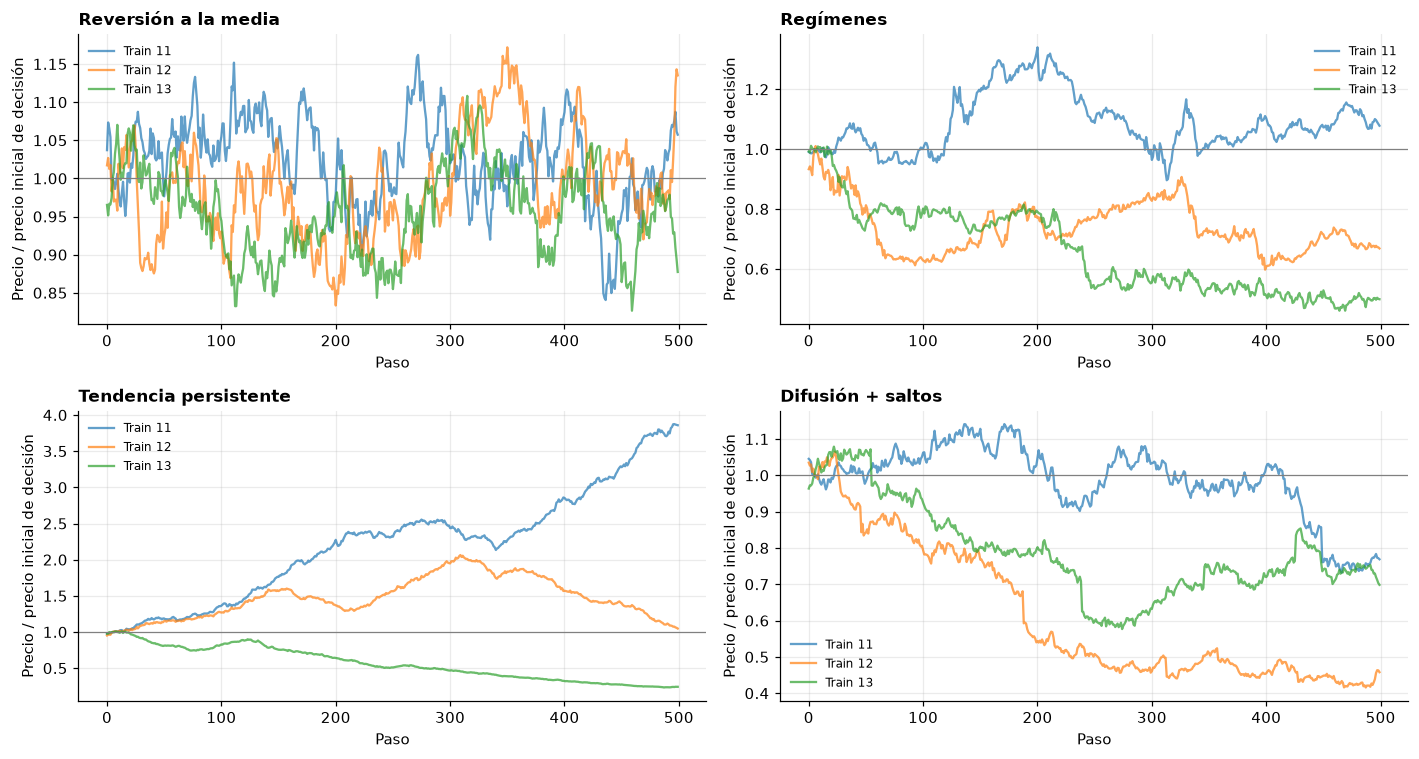

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for ax, market in zip(axes.flat, SYNTHETIC_MARKETS):
    for seed in (11, 12, 13):
        p = make_prices(market, N_STEPS, seed)
        ax.plot(p / p[5], alpha=.7, label=f"Train {seed}")
    ax.axhline(1, color="gray", lw=.8)
    ax.set_title(LABELS[market], loc="left"); ax.set_xlabel("Paso"); ax.set_ylabel("Precio / precio inicial de decisión")
    ax.legend(fontsize=8)
fig.tight_layout(); figure(fig, "03_mercados_extra"); plt.show()

## 4. Serie real y separación temporal

Se usa **SP500**, cierre diario del índice S&P 500 distribuido por [FRED / S&P Dow Jones Indices](https://fred.stlouisfed.org/series/SP500). El CSV local y su JSON de procedencia guardan URL, periodo, fecha de descarga y SHA-256. El notebook no necesita conexión para repetirse; se eliminan festivos sin cotización y no se interpolan precios.

Es un **índice de precios sin dividendos**, no un activo directamente negociable. El experimento simula una exposición fraccionaria al índice con la comisión del taller; omite dividendos, spread, deslizamiento e intereses del efectivo. Es una prueba histórica del algoritmo, no una estrategia operativa validada.

| Split | Fechas | Uso |
|---|---|---|
| Train | 2017–2021 | Cuantiles y episodios: ventanas contiguas aleatorias de 252 cierres, sin barajar los días |
| Validación | 2022–2023 | Diagnóstico fuera de train; política congelada |
| Test | 2024–2025 | Un único recorrido cronológico completo, sin actualizar Q |

Los episodios reales reutilizan ventanas solapadas **solo dentro del train**: no son nuevas historias independientes. Los indicadores de validación/test pueden usar precios anteriores al corte, que ya eran conocidos, pero los bins no se recalculan. Las cinco semillas miden variación del entrenamiento sobre la misma historia; **no equivalen a cinco mercados reales independientes**.

,inicio,fin,cierres
split,,,
train,2017-01-03,2021-12-31,1259
val,2022-01-03,2023-12-29,501
test,2024-01-02,2025-12-31,502


Fuente: https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500&cosd=2017-01-01&coed=2025-12-31
Descarga: 2026-10-28 · 2262 cierres


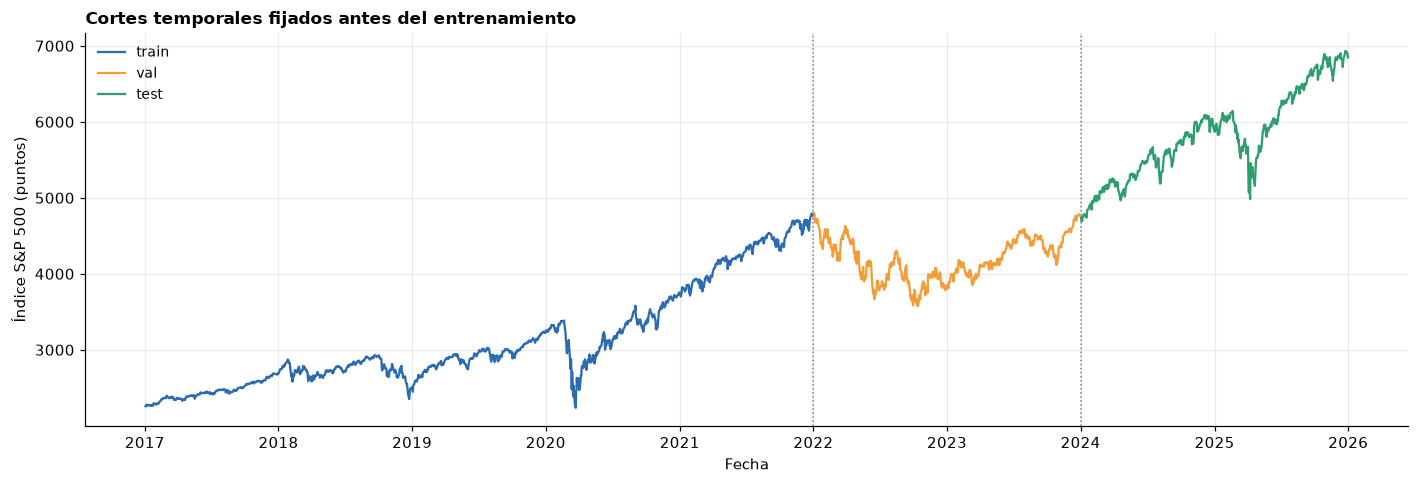

In [6]:
real_df, prepared_real = real_data()
metadata = json.loads((ROOT / "data/sp500_2017_2025.metadata.json").read_text(encoding="utf-8"))
split_rows = []
for split in ("train", "val", "test"):
    idx = real_indices(split)
    split_rows.append(dict(split=split, inicio=real_df.date.iloc[idx[0]].date(),
                           fin=real_df.date.iloc[idx[-1]].date(), cierres=len(idx)))
display(pd.DataFrame(split_rows).set_index("split"))
assert real_indices("train")[-1] < real_indices("val")[0]
assert real_indices("val")[-1] < real_indices("test")[0]
print(f"Fuente: {metadata['source_url']}\nDescarga: {metadata['retrieved_on']} · {metadata['observations']} cierres")

fig, ax = plt.subplots(figsize=(13, 4.5))
colors = {"train": AGENT_COLORS["qlearning"], "val": AGENT_COLORS["buy_hold"], "test": AGENT_COLORS["sarsa"]}
for split in ("train", "val", "test"):
    part = real_df.iloc[real_indices(split)]
    ax.plot(part.date, part.close, color=colors[split], label=split)
for cut in ("2022-01-01", "2024-01-01"):
    ax.axvline(pd.Timestamp(cut), color="gray", ls=":", lw=1)
ax.set_ylabel("Índice S&P 500 (puntos)"); ax.set_xlabel("Fecha")
ax.set_title("Cortes temporales fijados antes del entrenamiento", loc="left"); ax.legend()
fig.tight_layout(); figure(fig, "03_serie_real_splits"); plt.show()

## 5. Entrenamiento y validación

Se entrenan todas las combinaciones con el mismo presupuesto. La caché de `results/cache/03_extras/` identifica configuración, código fuente y datos mediante una huella: cambiar cualquiera de ellos invalida la entrada correspondiente. `RECALCULAR=True` fuerza el recálculo. El modo `NB_QUICK=1` utiliza nombres `_quick` y nunca sobrescribe los resultados completos.

Las curvas son **recompensa durante entrenamiento**, no rentabilidad de test. En datos reales, mejorar sobre ventanas ya reutilizadas puede ser sobreajuste. La convergencia usa la definición común del proyecto y es un indicador descriptivo; no certifica estabilidad ni optimalidad.

In [7]:
validacion = run_training(configs, "03_validacion" + SUF, n_jobs=N_JOBS, recompute=RECALCULAR)
display(validacion.groupby(["mercado", "agente"]).agg(
    retorno_val=("retorno_mediana", "median"), operaciones=("n_trades", "median"),
    estados=("n_estados", "first"), cobertura=("cobertura", "median"),
    segundos=("tiempo_s", "median")).style.format(
        {"retorno_val": "{:+.1%}", "operaciones": "{:.1f}", "cobertura": "{:.1%}", "segundos": "{:.2f}"}))

Entrenamiento/validación: 10/100 · 25 s


Entrenamiento/validación: 20/100 · 47 s


Entrenamiento/validación: 30/100 · 60 s


Entrenamiento/validación: 40/100 · 80 s


Entrenamiento/validación: 50/100 · 102 s


Entrenamiento/validación: 60/100 · 116 s


Entrenamiento/validación: 70/100 · 135 s


Entrenamiento/validación: 80/100 · 149 s


Entrenamiento/validación: 90/100 · 159 s


Entrenamiento/validación: 100/100 · 164 s


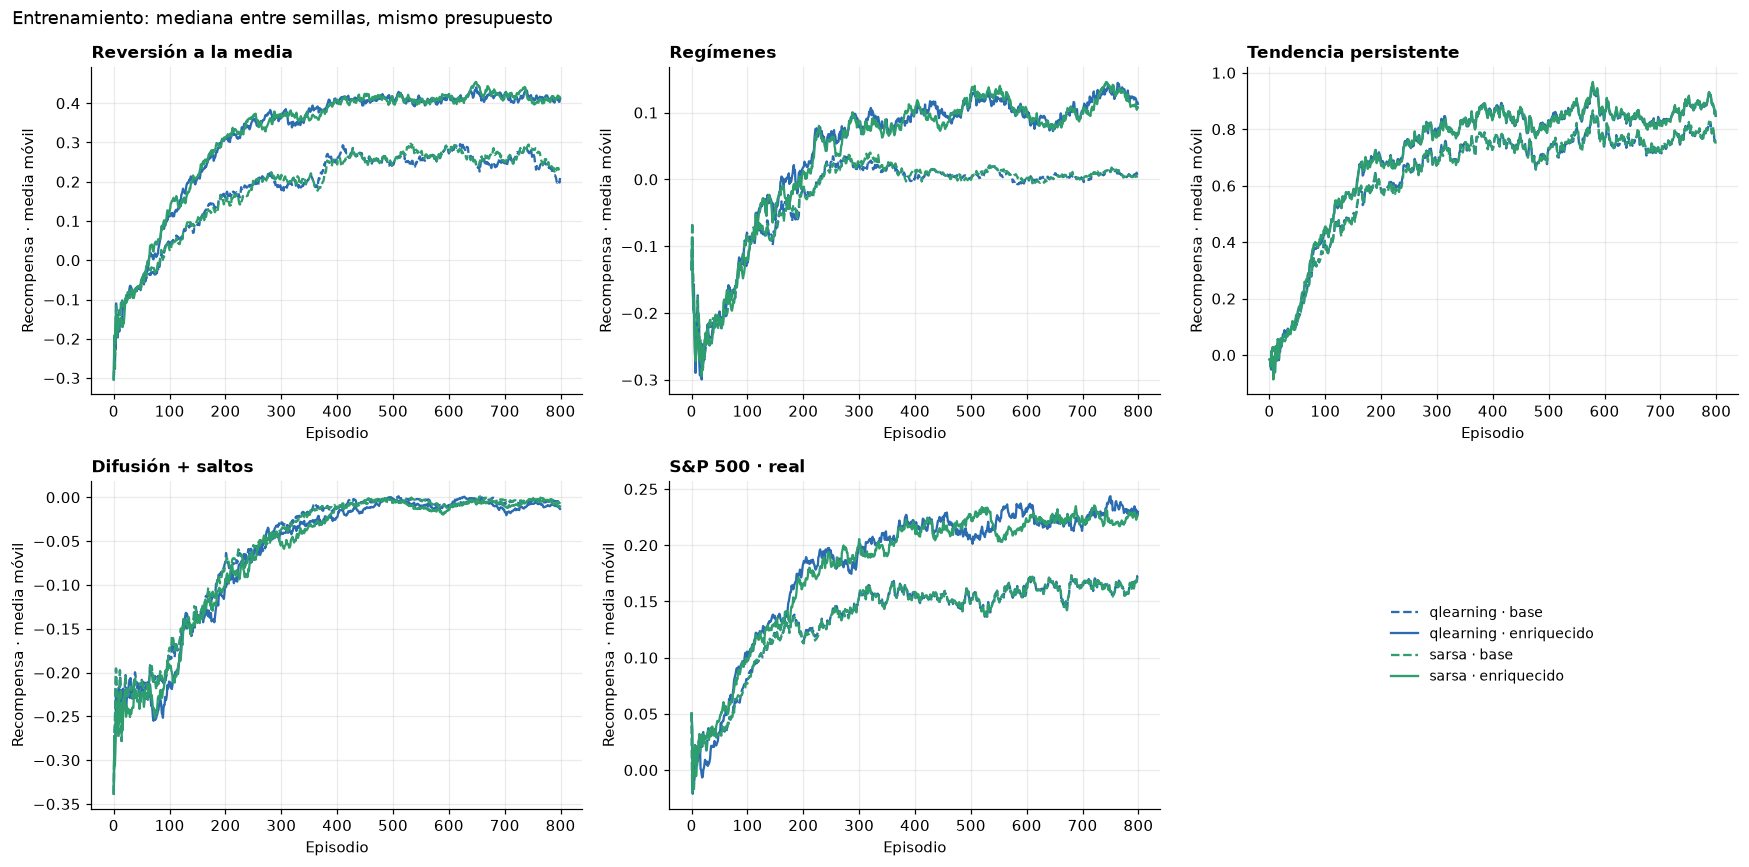

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, market in zip(axes.flat, MARKETS_03):
    for algorithm in ALGORITHMS:
        for state, linestyle in (("base", "--"), ("enriquecido", "-")):
            curves = []
            for cfg in configs:
                if (cfg["mercado"], cfg["algoritmo"], cfg["estado"]) == (market, algorithm, state):
                    _, _, _, rewards = load_model(cfg)
                    curves.append(pd.Series(rewards).rolling(min(50, N_EP), min_periods=1).mean().to_numpy())
            ax.plot(np.median(curves, axis=0), color=AGENT_COLORS[algorithm], ls=linestyle,
                    label=f"{algorithm} · {state}")
    ax.set_title(LABELS[market], loc="left"); ax.set_xlabel("Episodio"); ax.set_ylabel("Recompensa · media móvil")
axes.flat[-1].axis("off")
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center")
fig.suptitle("Entrenamiento: mediana entre semillas, mismo presupuesto", x=.01, ha="left")
fig.tight_layout(); figure(fig, "03_curvas_aprendizaje"); plt.show()

## 6. Test: rentabilidad, riesgo y operaciones

La tabla principal conserva `RESULT_COLUMNS`: mediana del retorno, media, desviación entre historias, Sharpe por paso, drawdown máximo medio, operaciones y convergencia/tiempo. Primero se calcula cada métrica por entrenamiento; después se toma la mediana entre semillas, igual que en 01–02.

En la serie real hay un único recorrido por política: su **desviación entre historias no es estimable** y queda vacía. El rango entre semillas se informa aparte. El resultado de no operar es cero; batir a buy & hold por permanecer en efectivo no demuestra capacidad predictiva.

In [9]:
semillas, episodios = run_test(configs, suffix=SUF, n_jobs=N_JOBS)
baseline_summary, baseline_paths = baselines(MARKETS_03, n_steps=N_STEPS, n_test=N_TEST)
numeric = [c for c in RESULT_COLUMNS if c not in ("agente", "mercado")]
learned = semillas.groupby(["mercado", "agente"], as_index=False)[numeric].median()
final = pd.concat([learned[RESULT_COLUMNS], baseline_summary[RESULT_COLUMNS]], ignore_index=True)
final = final.sort_values(["mercado", "agente"]).reset_index(drop=True)
save_results(final.to_dict("records"), "03_extras" + SUF)
baseline_paths.to_csv(RESULTS_DIR / f"03_baselines_episodios{SUF}.csv", index=False)
display(final.set_index(["mercado", "agente"])[
    ["retorno_mediana", "retorno_medio", "std", "sharpe", "max_drawdown", "n_trades", "episodios_convergencia", "tiempo_s"]
].style.format({"retorno_mediana": "{:+.1%}", "retorno_medio": "{:+.1%}", "std": "{:.1%}",
                "sharpe": "{:+.3f}", "max_drawdown": "{:.1%}", "n_trades": "{:.1f}", "tiempo_s": "{:.2f}"}, na_rep="—"))
print(f"Guardado: results/03_extras{SUF}.csv · {len(final)} filas")

Test: 10/100


Test: 20/100


Test: 30/100


Test: 40/100


Test: 50/100


...

Test: 70/100


Test: 80/100


Test: 90/100


Test: 100/100


Guardado: results/03_extras.csv · 35 filas


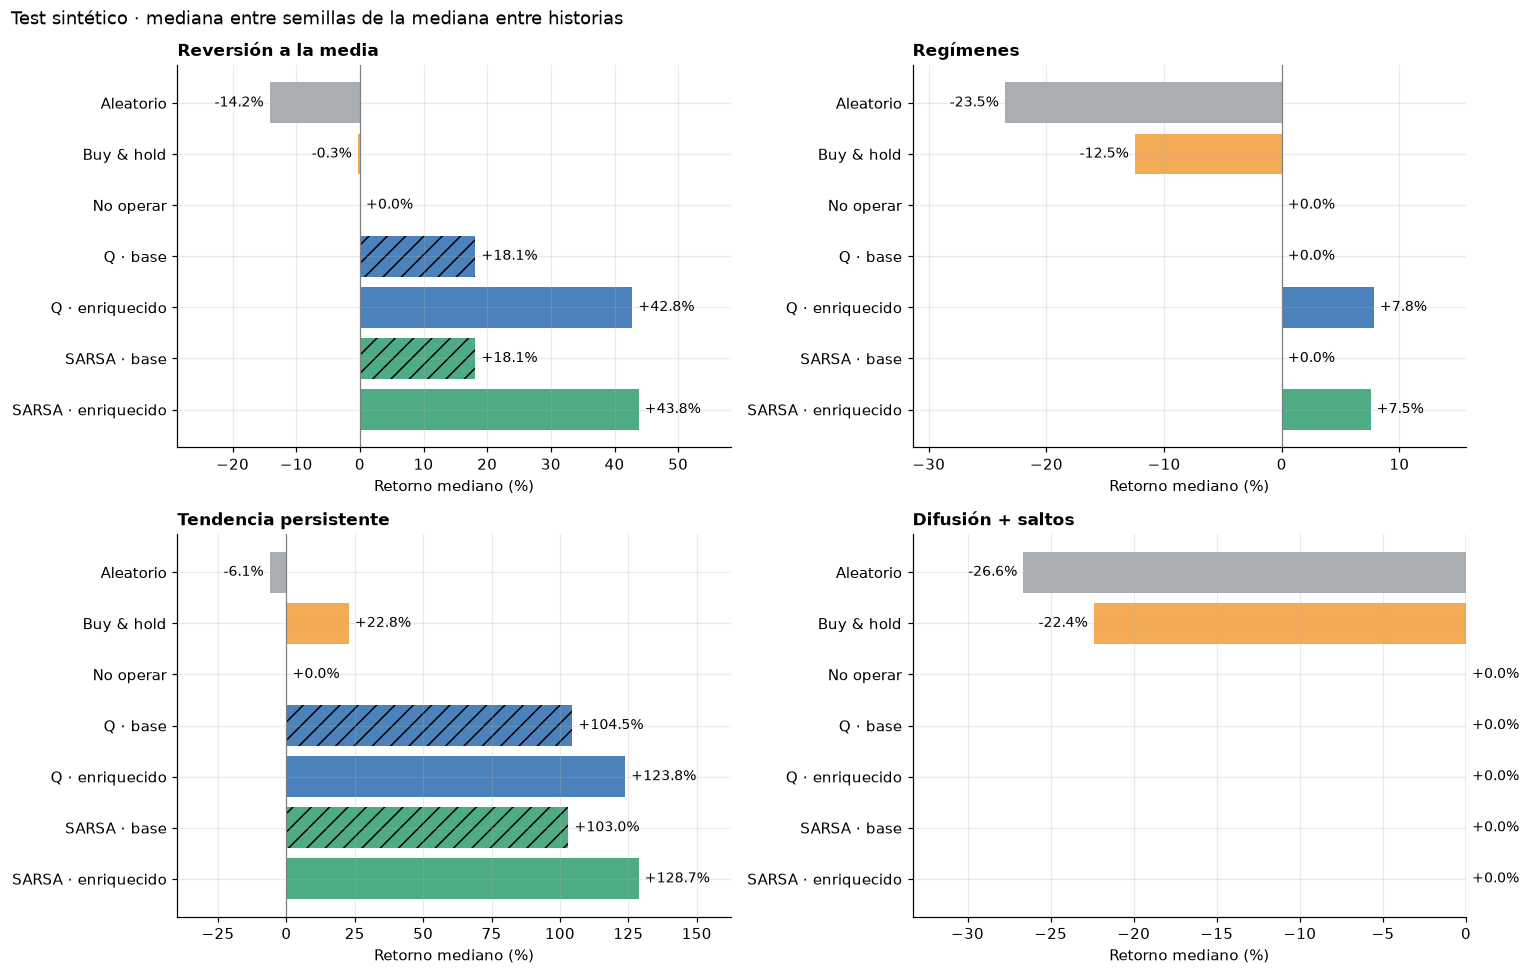

In [10]:
order = ["aleatorio", "buy_hold", "no_operar", "qlearning_base", "qlearning_enriquecido", "sarsa_base", "sarsa_enriquecido"]
names = ["Aleatorio", "Buy & hold", "No operar", "Q · base", "Q · enriquecido", "SARSA · base", "SARSA · enriquecido"]
bar_colors = [AGENT_COLORS["aleatorio"], AGENT_COLORS["buy_hold"], "#6B7280",
              AGENT_COLORS["qlearning"], AGENT_COLORS["qlearning"], AGENT_COLORS["sarsa"], AGENT_COLORS["sarsa"]]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, market in zip(axes.flat, SYNTHETIC_MARKETS):
    sub = final[final.mercado == market].set_index("agente").reindex(order)
    bars = ax.barh(names, 100*sub.retorno_mediana, color=bar_colors, alpha=.85)
    for j in (3, 5):
        bars[j].set_hatch("//")
    for bar, val in zip(bars, sub.retorno_mediana):
        ax.annotate(f"{val:+.1%}", (bar.get_width(), bar.get_y()+bar.get_height()/2),
                    xytext=(4 if val >= 0 else -4, 0), textcoords="offset points",
                    va="center", ha="left" if val >= 0 else "right", fontsize=9)
    ax.axvline(0, color="gray", lw=.8); ax.invert_yaxis(); ax.margins(x=.25)
    ax.set_title(LABELS[market], loc="left"); ax.set_xlabel("Retorno mediano (%)")
fig.suptitle("Test sintético · mediana entre semillas de la mediana entre historias", x=.01, ha="left")
fig.tight_layout(); figure(fig, "03_resultados_sinteticos"); plt.show()

### ¿Cuánto aporta el estado? Comparación emparejada

Cada política se evalúa en las mismas historias de test. Para cada historia se toma la mediana del retorno entre semillas y se resta **enriquecido − base**. La tabla muestra la mediana de esas diferencias, un intervalo bootstrap del 95 % (2 000 remuestreos de historias) y la fracción de historias donde mejora.

La mediana de diferencias no tiene por qué coincidir con la diferencia de medianas de la tabla anterior. El intervalo es **condicional a las cinco políticas entrenadas**: no incluye toda la incertidumbre de volver a entrenar ni corrige por comparaciones múltiples. No se aplica este bootstrap a la única historia real.

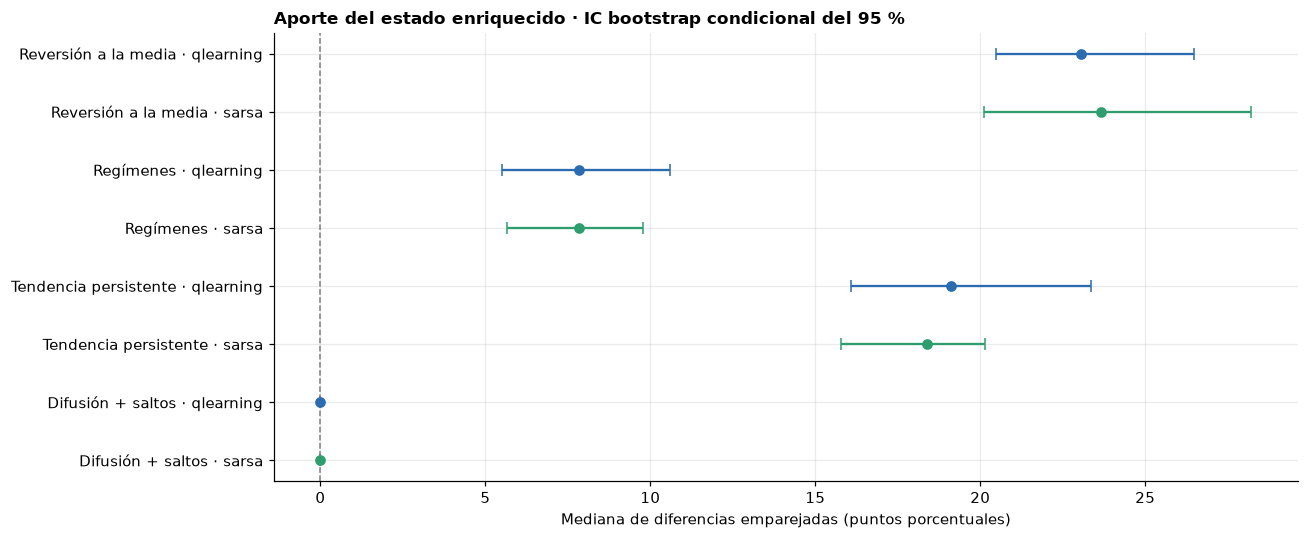

In [11]:
deltas = paired_state_effect(episodios)
deltas.to_csv(RESULTS_DIR / f"03_estado_deltas{SUF}.csv", index=False)
display(deltas.set_index(["mercado", "algoritmo"]).style.format(
    {"delta_mediana": "{:+.1%}", "ic95_inf": "{:+.1%}", "ic95_sup": "{:+.1%}", "fraccion_mejora": "{:.1%}"}))
fig, ax = plt.subplots(figsize=(12, 5))
for y, row in enumerate(deltas.itertuples()):
    ax.errorbar(100*row.delta_mediana, y,
                xerr=[[100*(row.delta_mediana-row.ic95_inf)], [100*(row.ic95_sup-row.delta_mediana)]],
                fmt="o", capsize=4, color=AGENT_COLORS[row.algoritmo])
ax.set_yticks(range(len(deltas)), [f"{LABELS[r.mercado]} · {r.algoritmo}" for r in deltas.itertuples()])
ax.axvline(0, color="gray", ls="--", lw=1); ax.invert_yaxis()
ax.set_xlabel("Mediana de diferencias emparejadas (puntos porcentuales)")
ax.set_title("Aporte del estado enriquecido · IC bootstrap condicional del 95 %", loc="left")
fig.tight_layout(); figure(fig, "03_aporte_estado"); plt.show()

### Cobertura del estado y coste del aprendizaje

La cobertura es la proporción de estados que se han visitado al menos una vez durante train, no la proporción de acciones bien aprendidas. Una cobertura alta tampoco garantiza suficientes visitas en las celdas infrecuentes. Se muestran mediana de visitas por celda y tiempo; este último incluye contención de los procesos y sirve como orientación en esta máquina.

In [12]:
coverage = semillas.groupby(["mercado", "estado"]).agg(
    estados=("n_estados", "first"), cobertura=("cobertura", "median"),
    visitas_mediana=("visitas_mediana", "median"), tiempo_s=("tiempo_s", "median"))
display(coverage.style.format({"cobertura": "{:.1%}", "visitas_mediana": "{:.0f}", "tiempo_s": "{:.2f}"}))
coverage.to_csv(RESULTS_DIR / f"03_cobertura{SUF}.csv")

## 7. Serie real: recorrido completo y bloques temporales

El gráfico de balance utiliza la **semilla 0, fijada de antemano**, no la que mejor salió en test. Las políticas están congeladas. Cada curva comienza con 1 000 y utiliza el mismo cierre inicial; se comparan también buy & hold y efectivo.

El resumen real informa el retorno completo y su rango entre entrenamientos. Después se reinicia el capital en bloques consecutivos de hasta 63 retornos diarios (se conserva un último bloque si tiene al menos 21). Estos bloques no solapan retornos, pero siguen siendo periodos relacionados de la misma historia. Se utilizan para mostrar heterogeneidad temporal, no como 200 muestras independientes ni como sustituto del recorrido completo.

,retorno_mediana,minimo_semilla,maximo_semilla,drawdown,operaciones
agente,,,,,
qlearning_base,+45.9%,+45.9%,+45.9%,18.9%,1
qlearning_enriquecido,+28.3%,+27.7%,+46.4%,11.4%,79
sarsa_base,+45.9%,+45.9%,+45.9%,18.9%,1
sarsa_enriquecido,+29.9%,+17.8%,+38.5%,12.8%,77


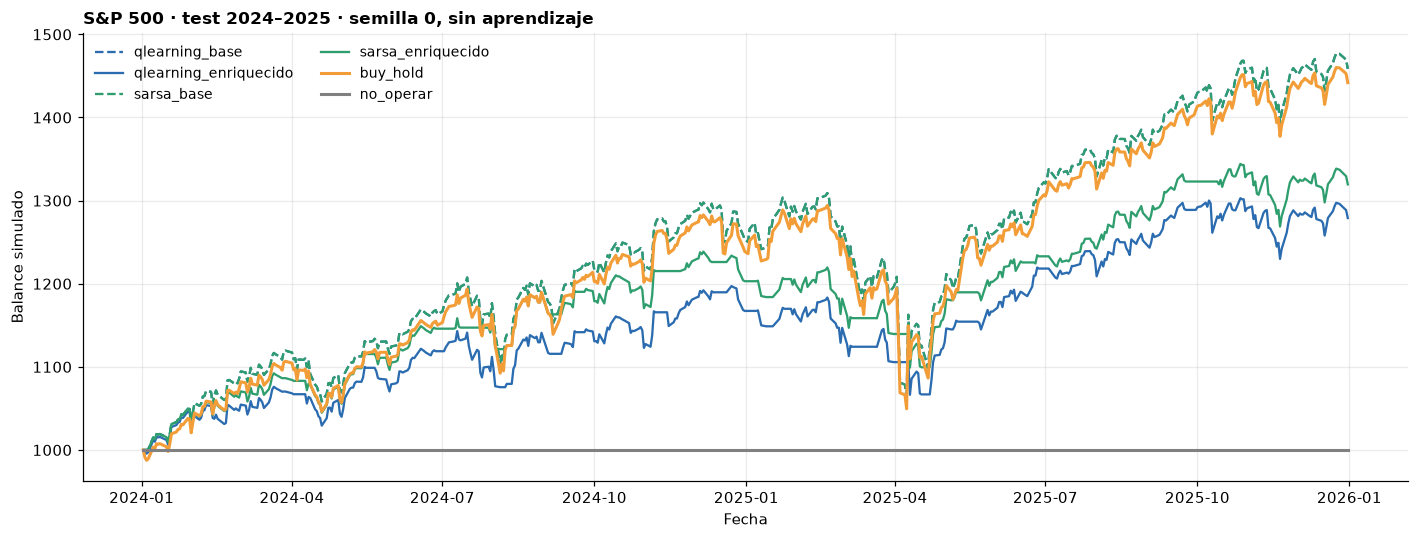

In [13]:
real_summary = semillas[semillas.mercado == "sp500_real"].groupby("agente").agg(
    retorno_mediana=("retorno_mediana", "median"), minimo_semilla=("retorno_mediana", "min"),
    maximo_semilla=("retorno_mediana", "max"), drawdown=("max_drawdown", "median"),
    operaciones=("n_trades", "median"))
display(real_summary.style.format({"retorno_mediana": "{:+.1%}", "minimo_semilla": "{:+.1%}",
                                  "maximo_semilla": "{:+.1%}", "drawdown": "{:.1%}", "operaciones": "{:.0f}"}))
test_real = evaluation_series("sp500_real", "test")[0]
fig, ax = plt.subplots(figsize=(13, 5))
block_rows = []
for cfg in configs:
    if cfg["mercado"] != "sp500_real":
        continue
    agent, encoder, row, _ = load_model(cfg)
    blocks = real_blocks(agent, encoder, seed=cfg["seed"])
    block_rows.extend(blocks.assign(agente=row["agente"], seed=cfg["seed"]).to_dict("records"))
    if cfg["seed"] == 0:
        _, balances, _, _ = run_extra_episode(test_real, agent, encoder)
        ax.plot(pd.to_datetime(test_real.dates[5:]), balances, color=AGENT_COLORS[cfg["algoritmo"]],
                ls="--" if cfg["estado"] == "base" else "-", label=row["agente"])
real_encoder = fit_encoder(calibration_series("sp500_real"))
for name, agent in (("buy_hold", BuyHoldAgent()), ("no_operar", CashAgent())):
    _, balances, _, _ = run_extra_episode(test_real, agent, real_encoder)
    ax.plot(pd.to_datetime(test_real.dates[5:]), balances,
            color=AGENT_COLORS["buy_hold"] if name == "buy_hold" else "gray", label=name, lw=2)
    blocks = real_blocks(agent, real_encoder)
    block_rows.extend(blocks.assign(agente=name, seed=-1).to_dict("records"))
ax.set_title("S&P 500 · test 2024–2025 · semilla 0, sin aprendizaje", loc="left")
ax.set_ylabel("Balance simulado"); ax.set_xlabel("Fecha"); ax.legend(ncol=2)
fig.tight_layout(); figure(fig, "03_real_balance"); plt.show()
blocks = pd.DataFrame(block_rows)
blocks.to_csv(RESULTS_DIR / f"03_real_bloques{SUF}.csv", index=False)

,agente,buy_hold,no_operar,qlearning_base,qlearning_enriquecido,sarsa_base,sarsa_enriquecido
fecha_inicio,fecha_fin,,,,,,
2024-01-02,2024-04-03,+9.8%,+0.0%,+11.0%,+6.7%,+11.0%,+6.6%
2024-04-03,2024-07-03,+6.1%,+0.0%,+6.1%,+6.8%,+6.1%,+7.9%
2024-07-03,2024-10-02,+3.0%,+0.0%,+2.5%,-0.3%,+2.5%,+0.4%
2024-10-02,2025-01-02,+2.7%,+0.0%,+2.7%,+1.8%,+2.7%,+2.4%
2025-01-02,2025-04-04,-13.6%,+0.0%,-13.6%,-6.2%,-13.6%,-8.7%
2025-04-04,2025-07-08,+22.6%,+0.0%,+22.6%,+10.1%,+22.6%,+12.3%
2025-07-08,2025-10-06,+8.2%,+0.0%,+8.2%,+7.6%,+8.2%,+7.1%
2025-10-06,2025-12-31,+1.5%,+0.0%,+1.8%,-0.6%,+1.8%,-0.6%


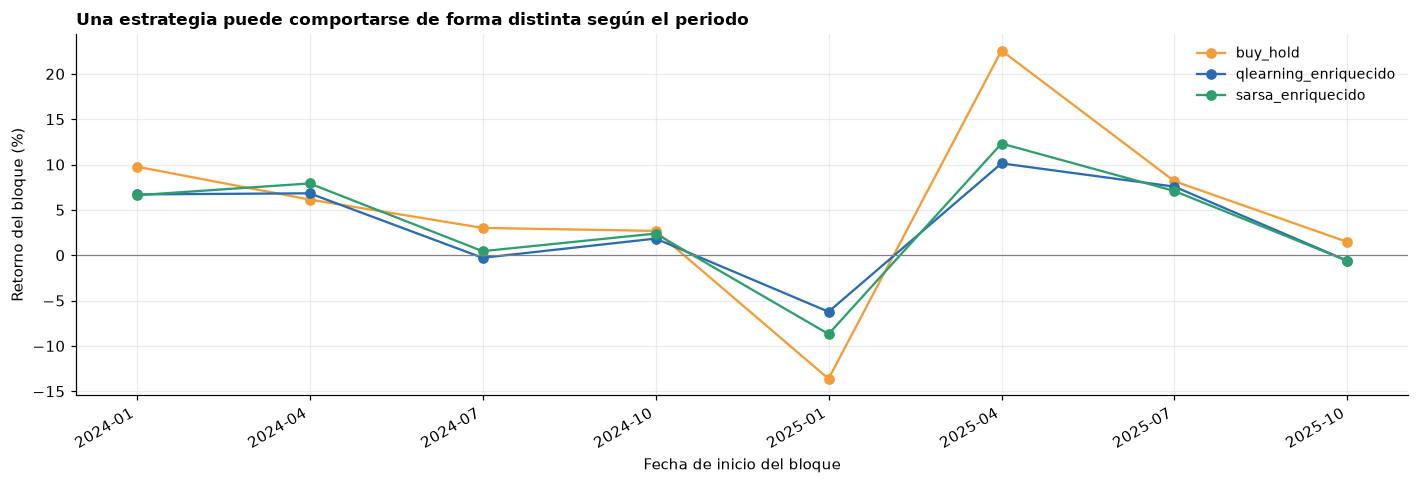

In [14]:
block_table = blocks.pivot_table(index=["fecha_inicio", "fecha_fin"], columns="agente", values="retorno", aggfunc="median")
display(block_table.style.format("{:+.1%}").set_caption("Retornos por bloque: mediana entre semillas; capital reiniciado en cada bloque"))
fig, ax = plt.subplots(figsize=(13, 4.5))
for agent_name in ["buy_hold", "qlearning_enriquecido", "sarsa_enriquecido"]:
    algo = agent_name.split("_")[0]
    color = AGENT_COLORS["buy_hold"] if agent_name == "buy_hold" else AGENT_COLORS[algo]
    ax.plot(np.arange(len(block_table)), 100*block_table[agent_name], marker="o", color=color, label=agent_name)
ax.axhline(0, color="gray", lw=.8)
ax.set_xticks(np.arange(len(block_table)), [a[:7] for a, b in block_table.index], rotation=30, ha="right")
ax.set_ylabel("Retorno del bloque (%)"); ax.set_xlabel("Fecha de inicio del bloque")
ax.set_title("Una estrategia puede comportarse de forma distinta según el periodo", loc="left"); ax.legend()
fig.tight_layout(); figure(fig, "03_real_bloques"); plt.show()

## 8. Conclusiones calculadas a partir de esta ejecución

Las conclusiones siguientes se generan con los resultados anteriores: también se conserva una versión Markdown en `results/03_conclusiones.md`. Un resultado de no operar o una mejora no concluyente se informa como tal.

In [15]:
lines = ["# 03 · Conclusiones de los extras", "",
         f"Ejecución {'rápida de comprobación' if QUICK else 'completa'}: {len(SEEDS)} semillas, {N_EP} episodios, "
         f"{N_TEST} historias sintéticas de test. Configuración fija y comparación emparejada.", "",
         "## Estado enriquecido", ""]
for r in deltas.itertuples():
    verdict = ("mejora con intervalo por encima de cero" if r.ic95_inf > 0 else
               "empeora con intervalo por debajo de cero" if r.ic95_sup < 0 else
               "sin mejora concluyente con este protocolo")
    lines.append(f"- **{LABELS[r.mercado]} · {r.algoritmo}:** {verdict}; mediana del delta {100*r.delta_mediana:+.1f} puntos porcentuales, "
                 f"IC95 condicional [{100*r.ic95_inf:+.1f}, {100*r.ic95_sup:+.1f}] puntos.")
lines += ["", "Los intervalos condicionan a las políticas entrenadas y no corrigen comparaciones múltiples. "
          "El estado crece de 20 a 180 celdas sin aumentar el presupuesto; esto mezcla información adicional y coste estadístico.",
          "", "## Mercados extra", ""]
for m in ("tendencia_persistente", "saltos"):
    sub = final[final.mercado == m].set_index("agente")
    q, sa, bh = [float(sub.loc[a, "retorno_mediana"]) for a in ("qlearning_enriquecido", "sarsa_enriquecido", "buy_hold")]
    lines.append(f"- **{LABELS[m]}:** Q enriquecido {q:+.1%}, SARSA enriquecido {sa:+.1%}, buy & hold {bh:+.1%}; efectivo 0 %.")
lines += ["", "La tendencia contiene persistencia aprovechable; los saltos son independientes. "
          "Superar buy & hold permaneciendo fuera no demuestra anticipación de saltos.", "", "## Serie real", ""]
bh_real = float(final[(final.mercado == "sp500_real") & (final.agente == "buy_hold")].retorno_mediana.iloc[0])
lines.append(f"- Buy & hold en el recorrido completo 2024–2025: **{bh_real:+.1%}**.")
for name in ("qlearning_base", "qlearning_enriquecido", "sarsa_base", "sarsa_enriquecido"):
    r = real_summary.loc[name]
    lines.append(f"- **{name}:** mediana {r.retorno_mediana:+.1%}, rango entre semillas "
                 f"[{r.minimo_semilla:+.1%}, {r.maximo_semilla:+.1%}], drawdown mediano {r.drawdown:.1%}, "
                 f"{r.operaciones:.0f} operaciones.")
for algorithm in ALGORITHMS:
    base_r = real_summary.loc[f"{algorithm}_base"]
    rich_r = real_summary.loc[f"{algorithm}_enriquecido"]
    direction = "más" if rich_r.retorno_mediana > base_r.retorno_mediana else "menos" if rich_r.retorno_mediana < base_r.retorno_mediana else "el mismo"
    risk = "menor" if rich_r.drawdown < base_r.drawdown else "mayor o igual"
    lines.append(f"- **Balance de la ampliación en {algorithm}:** {direction} retorno mediano y {risk} drawdown. "
                 "La evaluación exige leer ambas medidas conjuntamente.")
if all(real_summary.loc[f"{a}_base", "operaciones"] <= 1 for a in ALGORITHMS):
    lines += ["", "Los agentes base hacen como máximo una operación en mediana. Su diferencia frente a buy & hold "
              "puede proceder del momento de entrada; no implica haber aprendido una estrategia activa de anticipación."]
lines += ["", "La historia real de test es única y los entrenamientos reutilizan ventanas del pasado. "
          "No se puede inferir una ventaja persistente a partir de estos dos años ni de cinco semillas sobre los mismos precios. "
          "Los bloques muestran variación temporal, no nuevas historias independientes.",
          "", "## Límites y lectura crítica", "",
          "- Se conserva la recompensa del taller: suma retornos simples con comisión, mientras que el balance compone. "
          "Una mayor recompensa de entrenamiento no garantiza mayor rentabilidad final.",
          "- Los indicadores ampliados no garantizan un estado markoviano. La comparación no es una búsqueda exhaustiva de estados o hiperparámetros.",
          "- Se añaden MA30 y volatilidad conjuntamente: esta prueba no permite atribuir la mejora a cada indicador por separado.",
          "- La convergencia es un resumen descriptivo de la curva; puede reflejar el descenso de exploración y no una estrategia estable.",
          "- La evaluación real usa el índice de precios, sin dividendos, spread, deslizamiento ni intereses del efectivo; "
          "no es un activo directamente negociable y no constituye validación operativa.",
          "", "Fuente de la serie real: https://fred.stlouisfed.org/series/SP500. "
          f"{metadata['observations']} cierres; huella de los datos: `{metadata['sha256']}`."]
conclusions = "\n".join(lines)
(RESULTS_DIR / f"03_conclusiones{SUF}.md").write_text(conclusions + "\n", encoding="utf-8")
display(Markdown(conclusions))

manifest = dict(mode="quick" if QUICK else "full", configs=configs,
                source_fingerprint=code_fingerprint(), data=metadata,
                synthetic_test_series=N_TEST, real_test_paths=1, seeds=SEEDS,
                python=sys.version, numpy=np.__version__, pandas=pd.__version__)
(RESULTS_DIR / f"03_protocolo{SUF}.json").write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")
assert final[RESULT_COLUMNS].shape == (35, len(RESULT_COLUMNS))
assert final[["agente", "mercado"]].duplicated().sum() == 0
assert np.isfinite(final[["retorno_mediana", "retorno_medio", "sharpe", "max_drawdown", "n_trades"]]).all().all()
print("OK: tabla común, resultados por semilla/episodio, controles, figuras y protocolo guardados.")

# 03 · Conclusiones de los extras

Ejecución completa: 5 semillas, 800 episodios, 200 historias sintéticas de test. Configuración fija y comparación emparejada.

## Estado enriquecido

- **Reversión a la media · qlearning:** mejora con intervalo por encima de cero; mediana del delta +23.1 puntos porcentuales, IC95 condicional [+20.5, +26.5] puntos.
- **Reversión a la media · sarsa:** mejora con intervalo por encima de cero; mediana del delta +23.7 puntos porcentuales, IC95 condicional [+20.1, +28.2] puntos.
- **Regímenes · qlearning:** mejora con intervalo por encima de cero; mediana del delta +7.8 puntos porcentuales, IC95 condicional [+5.5, +10.6] puntos.
- **Regímenes · sarsa:** mejora con intervalo por encima de cero; mediana del delta +7.8 puntos porcentuales, IC95 condicional [+5.7, +9.8] puntos.
- **Tendencia persistente · qlearning:** mejora con intervalo por encima de cero; mediana del delta +19.1 puntos porcentuales, IC95 condicional [+16.1, +23.4] puntos.
- **Tendencia persistente · sarsa:** mejora con intervalo por encima de cero; mediana del delta +18.4 puntos porcentuales, IC95 condicional [+15.8, +20.1] puntos.
- **Difusión + saltos · qlearning:** sin mejora concluyente con este protocolo; mediana del delta +0.0 puntos porcentuales, IC95 condicional [+0.0, +0.0] puntos.
- **Difusión + saltos · sarsa:** sin mejora concluyente con este protocolo; mediana del delta +0.0 puntos porcentuales, IC95 condicional [+0.0, +0.0] puntos.

Los intervalos condicionan a las políticas entrenadas y no corrigen comparaciones múltiples. El estado crece de 20 a 180 celdas sin aumentar el presupuesto; esto mezcla información adicional y coste estadístico.

## Mercados extra

- **Tendencia persistente:** Q enriquecido +123.8%, SARSA enriquecido +128.7%, buy & hold +22.8%; efectivo 0 %.
- **Difusión + saltos:** Q enriquecido +0.0%, SARSA enriquecido +0.0%, buy & hold -22.4%; efectivo 0 %.

La tendencia contiene persistencia aprovechable; los saltos son independientes. Superar buy & hold permaneciendo fuera no demuestra anticipación de saltos.

## Serie real

- Buy & hold en el recorrido completo 2024–2025: **+44.2%**.
- **qlearning_base:** mediana +45.9%, rango entre semillas [+45.9%, +45.9%], drawdown mediano 18.9%, 1 operaciones.
- **qlearning_enriquecido:** mediana +28.3%, rango entre semillas [+27.7%, +46.4%], drawdown mediano 11.4%, 79 operaciones.
- **sarsa_base:** mediana +45.9%, rango entre semillas [+45.9%, +45.9%], drawdown mediano 18.9%, 1 operaciones.
- **sarsa_enriquecido:** mediana +29.9%, rango entre semillas [+17.8%, +38.5%], drawdown mediano 12.8%, 77 operaciones.
- **Balance de la ampliación en qlearning:** menos retorno mediano y menor drawdown. La evaluación exige leer ambas medidas conjuntamente.
- **Balance de la ampliación en sarsa:** menos retorno mediano y menor drawdown. La evaluación exige leer ambas medidas conjuntamente.

Los agentes base hacen como máximo una operación en mediana. Su diferencia frente a buy & hold puede proceder del momento de entrada; no implica haber aprendido una estrategia activa de anticipación.

La historia real de test es única y los entrenamientos reutilizan ventanas del pasado. No se puede inferir una ventaja persistente a partir de estos dos años ni de cinco semillas sobre los mismos precios. Los bloques muestran variación temporal, no nuevas historias independientes.

## Límites y lectura crítica

- Se conserva la recompensa del taller: suma retornos simples con comisión, mientras que el balance compone. Una mayor recompensa de entrenamiento no garantiza mayor rentabilidad final.
- Los indicadores ampliados no garantizan un estado markoviano. La comparación no es una búsqueda exhaustiva de estados o hiperparámetros.
- Se añaden MA30 y volatilidad conjuntamente: esta prueba no permite atribuir la mejora a cada indicador por separado.
- La convergencia es un resumen descriptivo de la curva; puede reflejar el descenso de exploración y no una estrategia estable.
- La evaluación real usa el índice de precios, sin dividendos, spread, deslizamiento ni intereses del efectivo; no es un activo directamente negociable y no constituye validación operativa.

Fuente de la serie real: https://fred.stlouisfed.org/series/SP500. 2262 cierres; huella de los datos: `39dc70d1cc353c0e89a1ef9d6c99be00930859a6460a553d2ef2ac5a8496f1dd`.

OK: tabla común, resultados por semilla/episodio, controles, figuras y protocolo guardados.
